# 05 · เปรียบเทียบผล

รัน notebook 01–04 ด้วย `%run` แล้วเก็บ `res` (ตาราง F1) และ `preds` (ผลทำนาย test) มาวาดรูปลง `figures/`

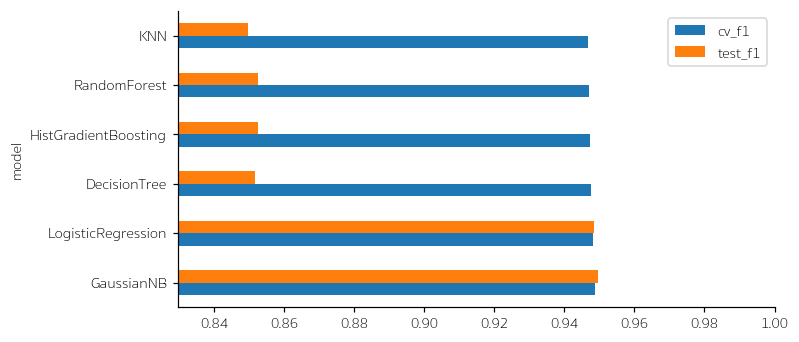

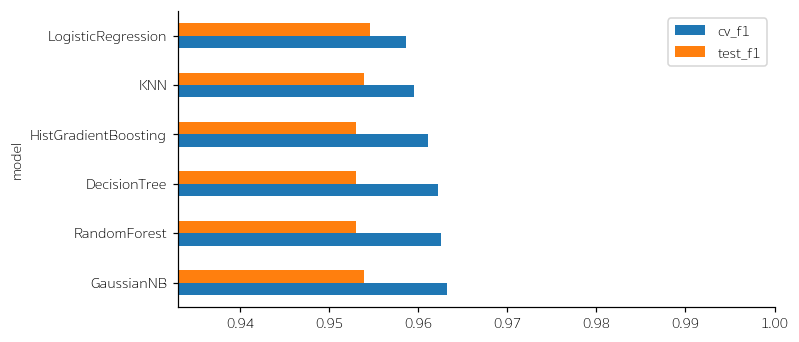

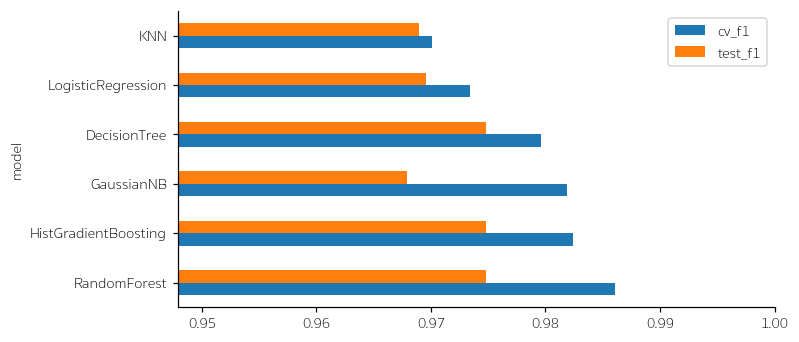

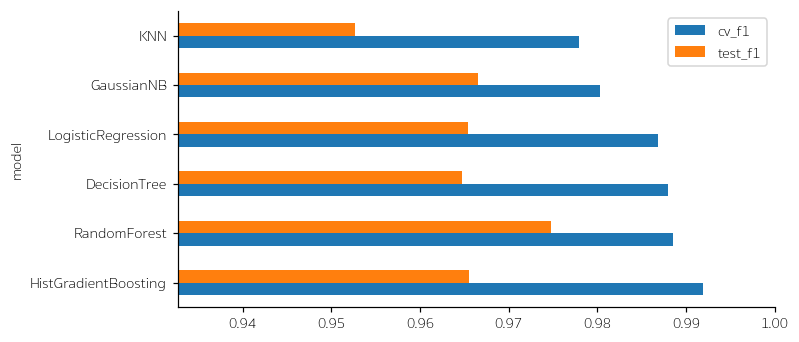

In [1]:
import os, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
plt.rcParams.update({"font.family": ["Sukhumvit Set", "DejaVu Sans"], "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

NB = {"01 แถวดิบ": "01_raw_rows", "02 window": "02_window_stats",
      "03 window+ประวัติ": "03_window_history", "04 ทุกเซนเซอร์": "04_all_sensors"}
UNIT = {"01 แถวดิบ": "แถว 0.5 s"}
ORDER = ["LogisticRegression", "DecisionTree", "RandomForest", "KNN", "GaussianNB", "HistGradientBoosting"]
R, P = {}, {}
for k, nb in NB.items():
    %run {nb}.ipynb
    plt.close("all")
    R[k], P[k] = res.set_index("model").loc[ORDER], (np.asarray(yte), preds)
    if nb.startswith("03"):
        te03, F03 = te.copy(), list(F)

## F1 ทุกวิธี × ทุกโมเดล

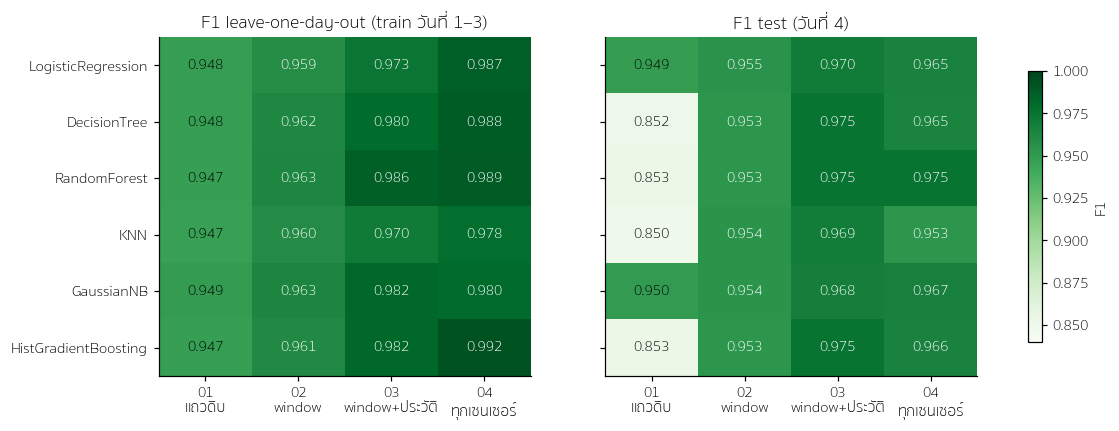

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, col, title in zip(ax, ["cv_f1", "test_f1"], ["F1 leave-one-day-out (train วันที่ 1–3)", "F1 test (วันที่ 4)"]):
    M = pd.DataFrame({k: r[col] for k, r in R.items()})
    im = a.imshow(M, cmap="Greens", vmin=0.84, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(M.values):
        a.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v > 0.95 else "black",
               weight="bold" if v == M.values.max() else "normal")
    a.set_xticks(range(M.shape[1]), [c.replace(" ", "\n", 1) for c in M.columns]); a.set_yticks(range(len(ORDER)), ORDER); a.set_title(title)
fig.colorbar(im, ax=ax, shrink=.8, label="F1")
fig.savefig("figures/f1_heatmap.png", bbox_inches="tight")

## Confusion matrix (test วันที่ 4)
แถว = ความจริง, คอลัมน์ = ที่ทำนาย · มุมขวาบน = **ไฟเปิดทิ้ง (FP)**, มุมซ้ายล่าง = **ตัดไฟใส่คน (FN)** ซึ่งแย่ที่สุด

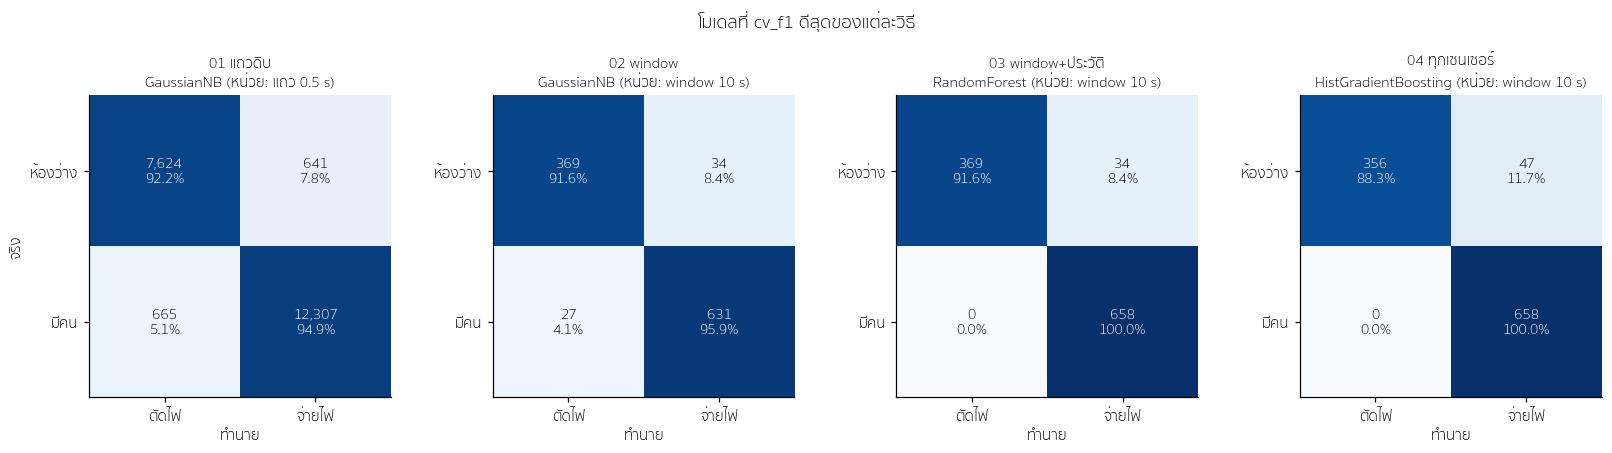

In [3]:
def cm_plot(a, y, p, title):
    cm = confusion_matrix(y, p, labels=[0, 1]); pct = cm / cm.sum(1, keepdims=True)
    a.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for (i, j), n in np.ndenumerate(cm):
        a.text(j, i, f"{n:,}\n{pct[i, j]:.1%}", ha="center", va="center", color="white" if pct[i, j] > .5 else "black")
    a.set_xticks([0, 1], ["ตัดไฟ", "จ่ายไฟ"]); a.set_yticks([0, 1], ["ห้องว่าง", "มีคน"])
    a.set_title(title, fontsize=10)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, (k, (y, pr)) in zip(ax, P.items()):
    best = R[k].cv_f1.idxmax()
    cm_plot(a, y, pr[best], f"{k}\n{best} (หน่วย: {UNIT.get(k, 'window 10 s')})")
    a.set_xlabel("ทำนาย")
ax[0].set_ylabel("จริง")
fig.suptitle("โมเดลที่ cv_f1 ดีสุดของแต่ละวิธี", y=1.02)
fig.tight_layout()
fig.savefig("figures/cm_methods.png", bbox_inches="tight")

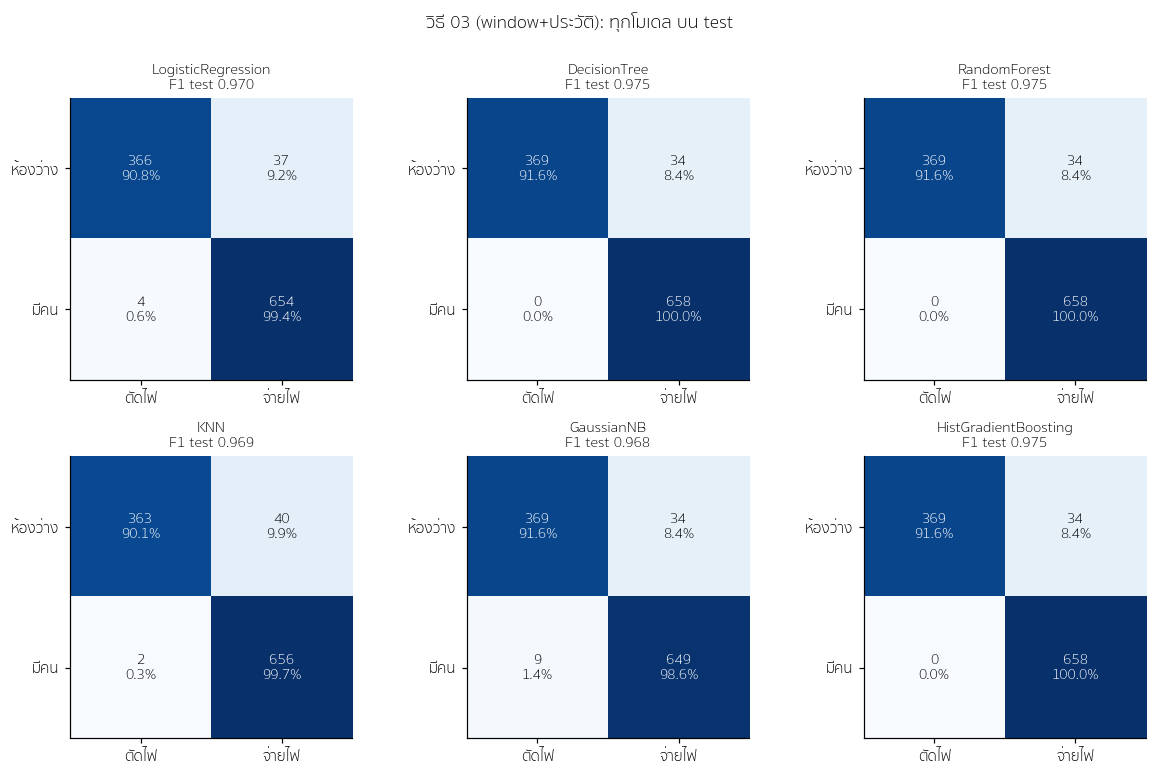

In [4]:
y, pr = P["03 window+ประวัติ"]
fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for a, m in zip(ax.flat, ORDER):
    cm_plot(a, y, pr[m], f"{m}\nF1 test {R['03 window+ประวัติ'].test_f1[m]:.3f}")
fig.suptitle("วิธี 03 (window+ประวัติ): ทุกโมเดล บน test", y=1.0)
fig.tight_layout()
fig.savefig("figures/cm_models_03.png", bbox_inches="tight")

## การ feed feature ให้การทำนาย 1 ครั้ง
บอร์ดเก็บค่าที่ 2 Hz ครบ 20 แถว (10 s) ก็สรุปเป็น feature 12 ตัว โดยแต่ละตัวมองย้อนหลังยาวต่างกัน แล้วส่งให้โมเดลทำนาย 1 ครั้ง
ตัวอย่างนี้เลือกจังหวะที่ห้องเพิ่งว่าง (label ยังเป็น 1 เพราะช่วงเผื่อ 30 s) จาก test วันที่ 4 ใช้โมเดลที่ deploy จริง (`../predictor_class/model.joblib`)

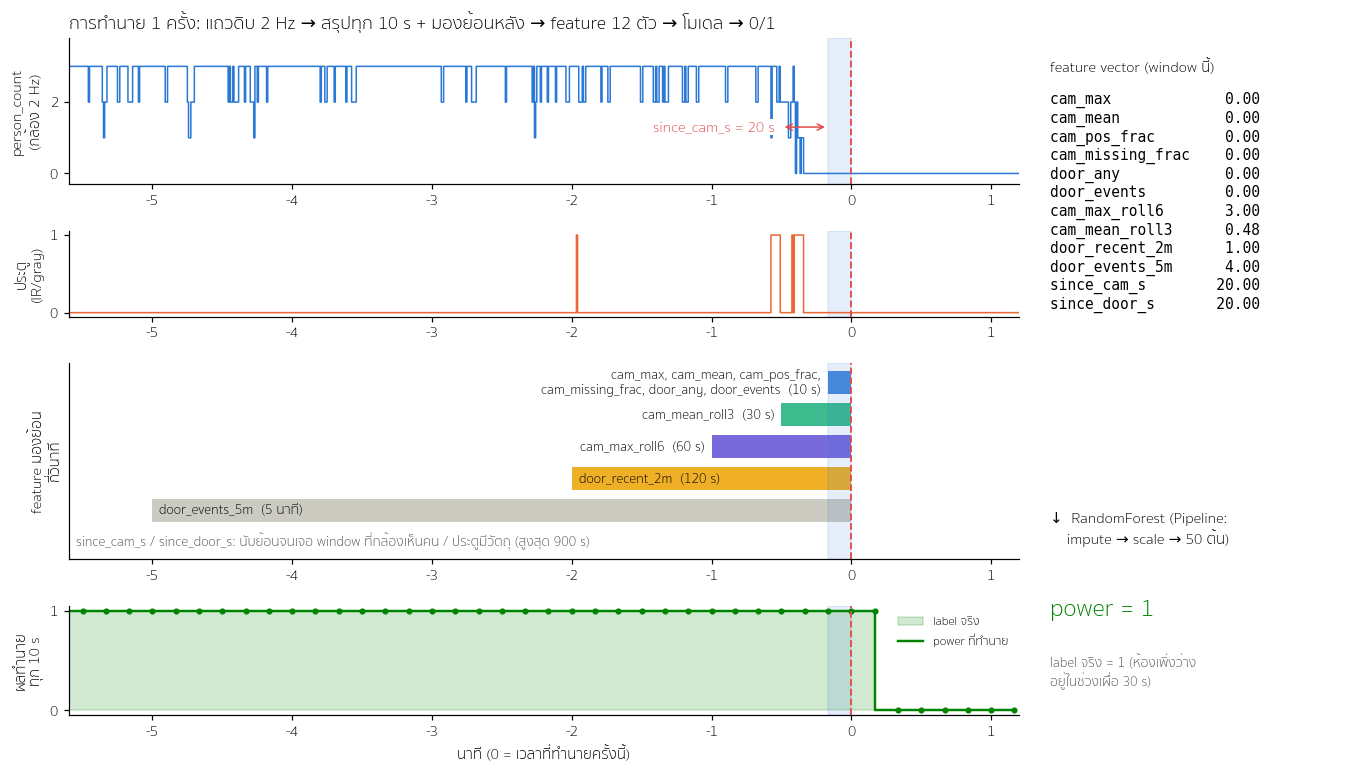

In [5]:
model = joblib.load("../predictor_class/model.joblib")
w = te03.reset_index(drop=True)
w["pred"] = model.predict(w[F03])
k = w.index[(w.label == 1) & (w.cam_max == 0) & (w.since_cam_s == 20) & (w.door_recent_2m == 1)][0]
raw = test.iloc[: (w.win.max() + 1) * 20].copy()            # test = 1 วัน 1 boot: window i = แถว 20i … 20i+19
raw["t"] = (np.arange(len(raw)) / 2 - (w.win[k] + 1) * 10) / 60   # นาที นับจากเวลาที่ทำนาย (จบ window ปัจจุบัน = 0)
raw = raw[raw.t.between(-5.6, 1.2)]
raw["door"] = ((raw.digital_do == 0) | (raw.analog_2_raw > 1000)).astype(int)
ww = w[w.win.between(w.win[k] - 34, w.win[k] + 7)].assign(t_end=lambda d: (d.win - w.win[k]) * 10 / 60)

fig = plt.figure(figsize=(15, 8))
g = fig.add_gridspec(4, 2, width_ratios=[3.2, 1], height_ratios=[1.2, .7, 1.6, .9], hspace=.35, wspace=.05)
a1, a2, a3, a4 = [fig.add_subplot(g[i, 0]) for i in range(4)]
for a in (a2, a3, a4): a.sharex(a1)
cur = (-1 / 6, 0)                                              # window ปัจจุบัน 10 s

a1.step(raw.t, raw.person_count.where(raw.person_count >= 0), where="post", lw=1, color="#2a78d6")
a1.set_ylabel("person_count\n(กล้อง 2 Hz)"); a1.set_ylim(-.3, raw.person_count.max() + .8)
last_seen = ww[(ww.cam_max > 0) & (ww.t_end <= 0)].t_end.max() - 1 / 6
a1.annotate("", xy=(cur[0], 1.3), xytext=(last_seen, 1.3), arrowprops=dict(arrowstyle="<->", color="#e34948"))
a1.text(last_seen - .05, 1.3, f"since_cam_s = {w.since_cam_s[k]:.0f} s", color="#e34948", ha="right", va="center",
        bbox=dict(fc="white", ec="none", pad=1))
a2.step(raw.t, raw.door, where="post", lw=1, color="#eb6834"); a2.set_ylabel("ประตู\n(IR/gray)"); a2.set_yticks([0, 1])

spans = [(5, "door_events_5m", "#c3c2b7"), (2, "door_recent_2m", "#eda100"), (1, "cam_max_roll6", "#6250d6"),
         (.5, "cam_mean_roll3", "#1baf7a"), (1 / 6, "cam_max, cam_mean, cam_pos_frac,\ncam_missing_frac, door_any, door_events", "#2a78d6")]
for i, (m, name, c) in enumerate(spans):
    a3.barh(i, m, left=-m, color=c, alpha=.85, height=.7)
    txt = f"{name}  ({m * 60:.0f} s)" if m < 5 else f"{name}  (5 นาที)"
    if m >= 2: a3.text(-m + .05, i, txt, ha="left", va="center", fontsize=9)       # bar ยาว: เขียนในแท่ง
    else: a3.text(-m - .05, i, txt, ha="right", va="center", fontsize=9)
a3.set_yticks([]); a3.set_ylabel("feature มองย้อน\nกี่วินาที")
a3.text(-5.55, -1.1, "since_cam_s / since_door_s: นับย้อนจนเจอ window ที่กล้องเห็นคน / ประตูมีวัตถุ (สูงสุด 900 s)", fontsize=9, color="#52514e")
a3.set_ylim(-1.5, len(spans) - .4)

a4.fill_between(ww.t_end, ww.label, step="pre", color="#008300", alpha=.18, label="label จริง")
a4.step(ww.t_end, ww.pred, where="pre", color="#008300", lw=1.6, label="power ที่ทำนาย")
a4.plot(ww.t_end, ww.pred, "o", color="#008300", ms=3)
a4.set_ylabel("ผลทำนาย\nทุก 10 s"); a4.set_yticks([0, 1]); a4.legend(loc="upper right", fontsize=8, frameon=False)
a4.set_xlabel("นาที (0 = เวลาที่ทำนายครั้งนี้)")
for a in (a1, a2, a3, a4):
    a.axvspan(*cur, color="#2a78d6", alpha=.12); a.axvline(0, color="#e34948", lw=1.2, ls="--")
a1.set_xlim(-5.6, 1.2)
a1.set_title("การทำนาย 1 ครั้ง: แถวดิบ 2 Hz → สรุปทุก 10 s + มองย้อนหลัง → feature 12 ตัว → โมเดล → 0/1", loc="left")

at = fig.add_subplot(g[:, 1]); at.axis("off")
rows = "\n".join(f"{f:<17}{w.loc[k, f]:>7.2f}" for f in F03)
at.text(0, .97, "feature vector (window นี้)", weight="bold", va="top")
at.text(0, .92, rows, family="monospace", va="top", fontsize=9.5)
at.text(0, .30, "↓  RandomForest (Pipeline:\n    impute → scale → 50 ต้น)", va="top")
at.text(0, .17, f"power = {w.pred[k]}", va="top", fontsize=16, weight="bold", color="#008300")
at.text(0, .09, f"label จริง = {w.label[k]} (ห้องเพิ่งว่าง\nอยู่ในช่วงเผื่อ 30 s)", va="top", fontsize=9, color="#52514e")
fig.savefig("figures/feature_feed.png", bbox_inches="tight")